<a href="https://colab.research.google.com/github/AntsTorim/Teadusseminarid/blob/main/MaatriksVektor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


Pythoni teek [NumPy](http://numpy.org) on süvaõppe raamistike kontseptuaalne ja ajalooline vundament. Algselt on päritolu akadeemiline, Eestist on seal näiteks Pearu Petersoni panus.  Hilisemad närvivõrkude ja süvaõppe teegid TensorFlow ja PyTorch on lisasid GPU-arvutuse jms. Suured keelemudelid (LLM) on omakorda nendes raamistikes tehtud tensorarvutused, mida treenitakse väga suures mastaabis.

NumPy põhiobjekt on massiiv (*array*), millele matemaatikas vastab tensori mõiste (vt Google *tensorflow* süvaõppe teek).

Vektor on esimest järku tensor, ühemõõtmeline massiiv.

In [ ]:
a = np.array([2, 1])
b = np.array([1, -1])

Vektorite liitmine liidab nende vastavad komponendid.





In [ ]:
a+b

array([3, 0])

In [ ]:
def plt_vect_from_origin(vectors):
  assert len(vectors) < 21
  dim = np.abs(vectors).max() + 1
  origin = np.zeros((len(vectors), 2))
  colors = plt.cm.tab20(np.arange(len(vectors)))
  fig, ax = plt.subplots()
  ax.quiver(origin[:, 0], origin[:, 1], vectors[:, 0], vectors[:, 1],
            angles='xy', scale_units='xy', scale=1,
            color=colors)
  ax.set_xlim(-dim, dim); ax.set_ylim(-dim, dim)
  ax.set_aspect('equal')
  ax.grid(True); ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
  plt.show()

In [ ]:

vects = np.array([[2, 1], [-1, -8], [3, -2], [-5, 5]])


Vektori geomeetrilises esituses näidatakse neid nooltena.

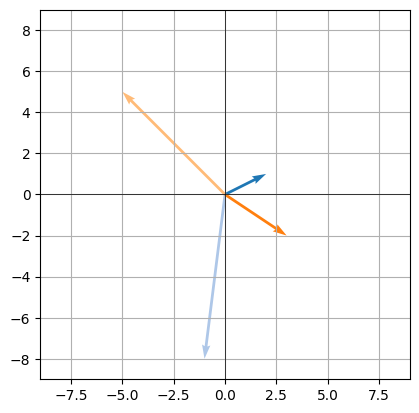

In [ ]:

plt_vect_from_origin(vects)

Vektori korrutamine skalaariga (arv, nullindat kärku tensor) korrutab vektori kõik komponendid arvuga läbi. Toimub vektori venitamine st skaleerimine.

In [ ]:
vects[0] = 3*vects[0]

In [ ]:
vects

array([[ 6,  3],
       [-1, -8],
       [ 3, -2],
       [-5,  5]])

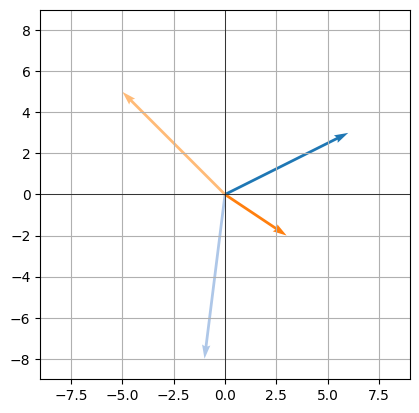

In [ ]:
plt_vect_from_origin(vects)

Standardsed baasivektorid kahemõõtmelises ruumis on ühikpikkusega, asuvad x, y telgedel ja on seega ortogonaalsed.

In [ ]:
ortho = np.array([[1, 0], [0, 1]])

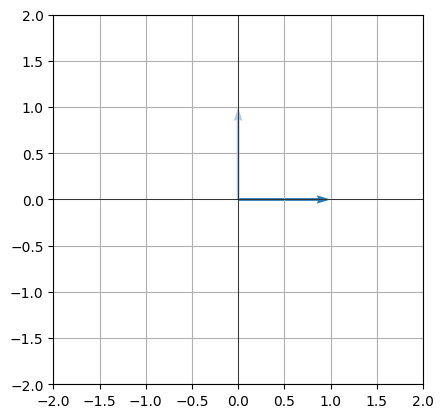

In [ ]:
plt_vect_from_origin(ortho)

Vektorite lineaarne kate koosneb kõigist vektoritest, kuhu antud vektorite skaleerimise ja liitmisega - nö lineaarse kombinatsiooniga - jõuda saab. Paralleelsete vektorite lineaarne kate on näiteks ühemõõtmeline joon. Sellisel juhul võib ühe vektori ära jätta ilma lineaarset katet vähendamata ja öeldakse, et vektorid on lineaarselt sõltuvad.

In [ ]:
2*a - 7*b

array([-3,  9])

Lineaarne teisendus $T$ teisendab sisendvektori väljundvektoriks säilitades samal ajal vektorite lineaarkombinatsioonid:
 $$T(c\mathbf{u} + d\mathbf{v}) = cT(\mathbf{u}) + dT(\mathbf{v})$$

 Teisiti öeldes jään nullpunkt samaks ja kõik jooned jäävad joonteks.

Maatriks on kahemõõtmeline tensor/massiiv. Kui meil on tegu ruutmaatriksiga, siis lineaarse teisendusena kirjeldab see oma ridada/veergudega, kuidas teisenduvad standardsed baasivektorid.

In [ ]:
transform = np.array([[1, 0],
                      [-1, 2]])

In [ ]:
ortho

array([[1, 0],
       [0, 1]])

In [ ]:
ortho[0] @ transform

array([1, 0])

In [ ]:
ortho[1] @ transform

array([-1,  2])

Baasivektorite maatriks on ühikmaatriks $I$ (peadiagonaalil ühed, mujal nullid) st selle korrutamine suvalise maatriksiga $A$ jätab selle maatriksi muutmatuks $IA=A$.

In [ ]:
ortho @ transform

array([[ 1,  0],
       [-1,  2]])

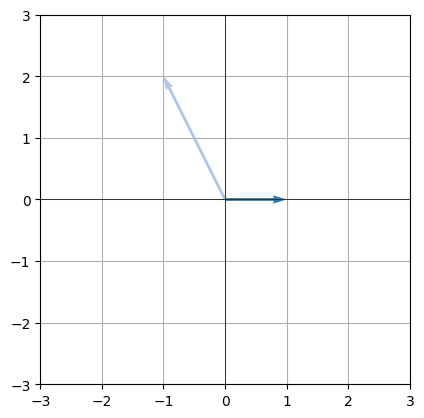

In [ ]:
plt_vect_from_origin(ortho@transform)

In [ ]:
a

array([2, 1])

In [ ]:
a @ transform

array([1, 2])

In [ ]:
vects @ transform

array([[  3,   6],
       [  7, -16],
       [  5,  -4],
       [-10,  10]])

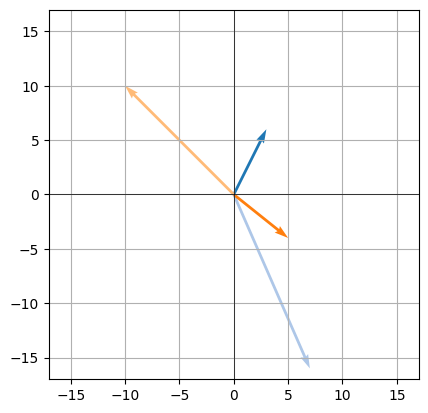

In [ ]:
plt_vect_from_origin(vects@transform)

In [ ]:
rotate = np.array([[0, 1],
                  [-1, 0]])

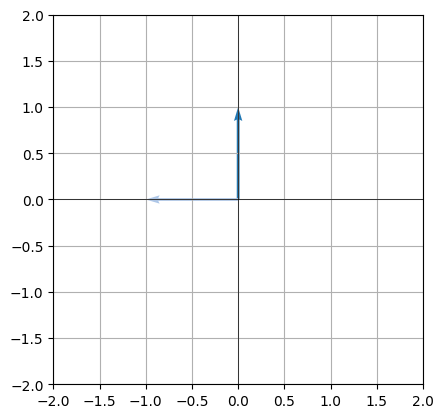

In [ ]:
plt_vect_from_origin(ortho@rotate)

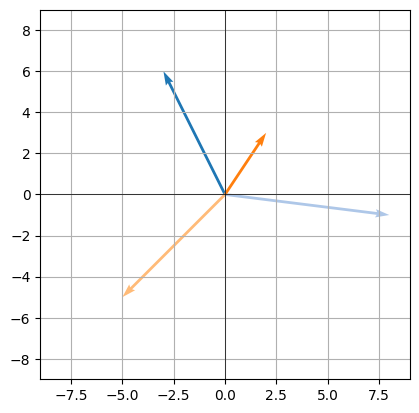

In [ ]:
plt_vect_from_origin(vects@rotate)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

def plot_basis_grid(b1, b2, lim=5, ax=None, v=None):
    B = np.column_stack([b1, b2]).astype(float)
    if abs(np.linalg.det(B)) < 1e-12:
        raise ValueError("b1 and b2 are parallel – not a basis")
    b1, b2 = B[:, 0], B[:, 1]
    ax = ax or plt.gca()

    # View corners expressed in the new basis -> which integer lines are needed
    corners = np.array([[-lim, -lim], [lim, -lim], [lim, lim], [-lim, lim]]).T
    c = np.linalg.solve(B, corners)
    lo = np.floor(c.min(axis=1)).astype(int)
    hi = np.ceil(c.max(axis=1)).astype(int)

    # Lines parallel to b2 (through i*b1) and parallel to b1 (through j*b2)
    segs  = [[i*b1 + lo[1]*b2, i*b1 + hi[1]*b2] for i in range(lo[0], hi[0] + 1)]
    segs += [[j*b2 + lo[0]*b1, j*b2 + hi[0]*b1] for j in range(lo[1], hi[1] + 1)]
    ax.add_collection(LineCollection(segs, colors='steelblue', lw=0.7, alpha=0.6))

    # New "axes" (i=0, j=0) a bit stronger
    ax.add_collection(LineCollection(
        [[lo[1]*b2, hi[1]*b2], [lo[0]*b1, hi[0]*b1]], colors='steelblue', lw=1.5))

    # Unit cell (its area = |det B|)
    ax.fill(*np.array([[0, 0], b1, b1 + b2, b2]).T, color='gold', alpha=0.3)

    # Basis vectors
    ax.quiver([0, 0], [0, 0], [b1[0], b2[0]], [b1[1], b2[1]],
              angles='xy', scale_units='xy', scale=1,
              color=['crimson', 'darkgreen'], width=0.008, zorder=3)
    ax.annotate('$b_1$', b1, color='crimson', fontsize=13)
    ax.annotate('$b_2$', b2, color='darkgreen', fontsize=13)

    # Optional: vector given by its coordinates (a, b) in the new basis
    if v is not None:
        a, b = v
        p = a*b1 + b*b2
        ax.plot(*np.array([[0, 0], a*b1, p]).T, 'k--', lw=1)   # path a*b1 then b*b2
        ax.quiver(0, 0, *p, angles='xy', scale_units='xy', scale=1, color='k', zorder=4)
        ax.annotate(f'({a}, {b}) → ({p[0]:.2f}, {p[1]:.2f})', p, fontsize=10)

    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_aspect('equal')
    ax.grid(alpha=0.25)            # the ordinary standard grid, faint, for comparison
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
    plt.show()




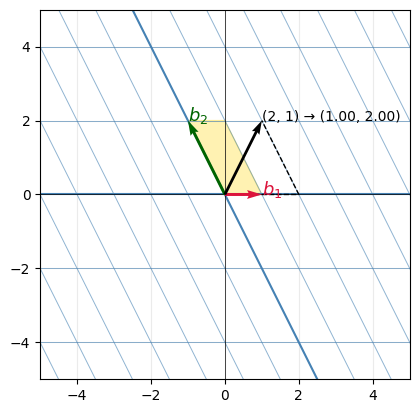

In [ ]:
plot_basis_grid(b1=ortho@transform[0], b2=ortho@transform[1], lim=5, v=(2, 1))

In [ ]:
import torch
import torch.nn as nn

In [ ]:
layer = nn.Linear(2, 2, bias=False)
with torch.no_grad():
    layer.weight.copy_(torch.tensor([[2.0, 1.0],
                                     [0.0, 1.0]]))

In [ ]:
layer.weight

Parameter containing:
tensor([[2., 1.],
        [0., 1.]], requires_grad=True)

In [ ]:
square = torch.tensor([[0.0, 0.0],
                       [1.0, 0.0],
                       [1.0, 1.0],
                       [0.0, 1.0]])

In [ ]:
print(layer(square))    # venitatud rööpküliku nurgad

tensor([[0., 0.],
        [2., 0.],
        [3., 1.],
        [1., 1.]], grad_fn=<MmBackward0>)


In [ ]:
square @ layer.weight.T   # True

tensor([[0., 0.],
        [2., 0.],
        [3., 1.],
        [1., 1.]], grad_fn=<MmBackward0>)